## Project: Bankruptcy Prevention

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Bankruptcy_prevention_dataset.csv", sep=";")

In [3]:
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [4]:
df.tail()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy
249,1.0,0.0,0.5,0.5,1.0,1.0,non-bankruptcy


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   industrial_risk         250 non-null    float64
 1    management_risk        250 non-null    float64
 2    financial_flexibility  250 non-null    float64
 3    credibility            250 non-null    float64
 4    competitiveness        250 non-null    float64
 5    operating_risk         250 non-null    float64
 6    class                  250 non-null    str    
dtypes: float64(6), str(1)
memory usage: 16.8 KB


In [6]:
df.shape

(250, 7)

In [7]:
df.columns

Index(['industrial_risk', ' management_risk', ' financial_flexibility',
       ' credibility', ' competitiveness', ' operating_risk', ' class'],
      dtype='str')

In [8]:
# Check missing values
print(df.isnull().sum())

industrial_risk           0
 management_risk          0
 financial_flexibility    0
 credibility              0
 competitiveness          0
 operating_risk           0
 class                    0
dtype: int64


In [9]:
# Check duplicate records
df.duplicated().sum()

np.int64(147)

In [10]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['industrial_risk', 'management_risk', 'financial_flexibility', 'credibility', 'competitiveness', 'operating_risk', 'class']


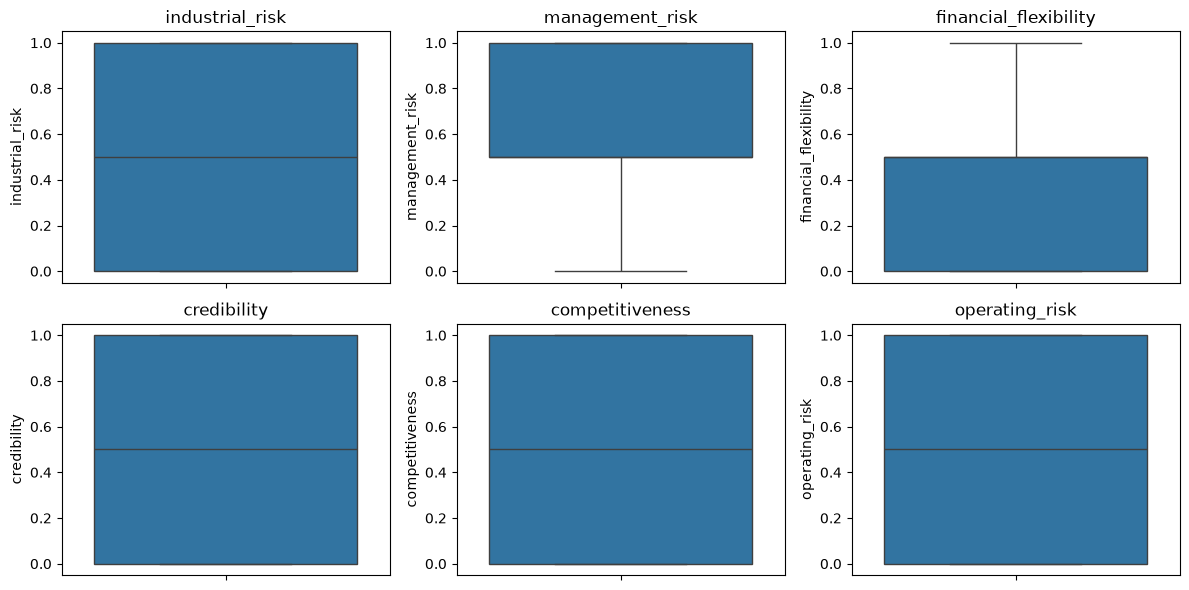

In [11]:
## Outlier Check
# Import the plotting library
import matplotlib.pyplot as plt
import seaborn as sns

# Select only the input features, excluding the target
features = df.columns.drop("class")

# Create a boxplot for each feature
plt.figure(figsize=(12, 6))

for i, column in enumerate(features, start=1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()


In [12]:

# Check potential outliers using the IQR method

for column in features:

    # Find the first and third quartiles
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the lower and upper boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify values outside the boundaries
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nFeature: {column}")
    print("Potential outliers:", len(outliers))
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)



Feature: industrial_risk
Potential outliers: 0
Lower bound: -1.5
Upper bound: 2.5

Feature: management_risk
Potential outliers: 0
Lower bound: -0.25
Upper bound: 1.75

Feature: financial_flexibility
Potential outliers: 0
Lower bound: -0.75
Upper bound: 1.25

Feature: credibility
Potential outliers: 0
Lower bound: -1.5
Upper bound: 2.5

Feature: competitiveness
Potential outliers: 0
Lower bound: -1.5
Upper bound: 2.5

Feature: operating_risk
Potential outliers: 0
Lower bound: -1.5
Upper bound: 2.5



Distribution of industrial_risk:
industrial_risk
0.0    80
0.5    81
1.0    89
Name: count, dtype: int64


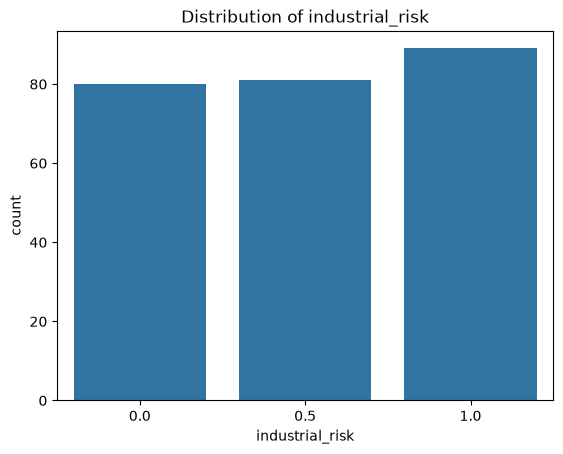


Distribution of management_risk:
management_risk
0.0     62
0.5     69
1.0    119
Name: count, dtype: int64


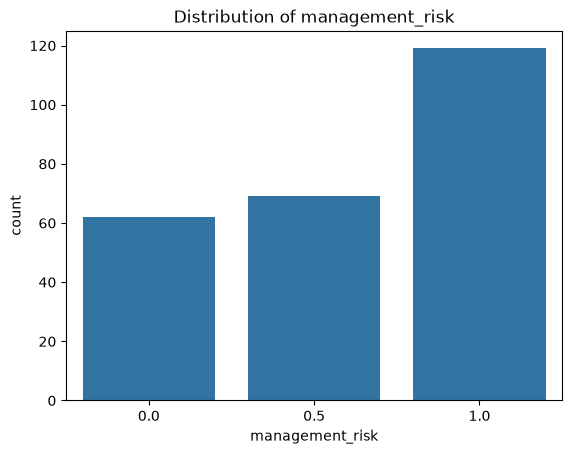


Distribution of financial_flexibility:
financial_flexibility
0.0    119
0.5     74
1.0     57
Name: count, dtype: int64


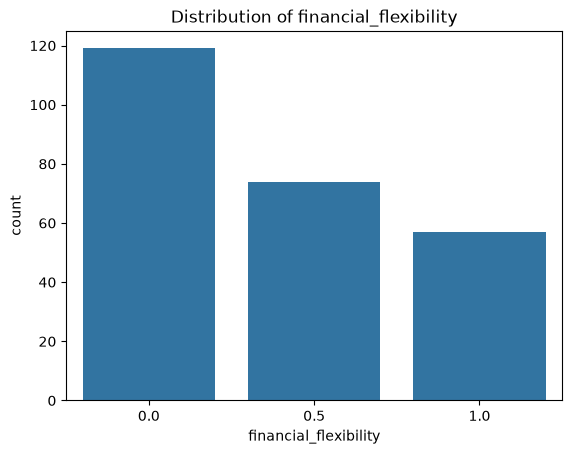


Distribution of credibility:
credibility
0.0    94
0.5    77
1.0    79
Name: count, dtype: int64


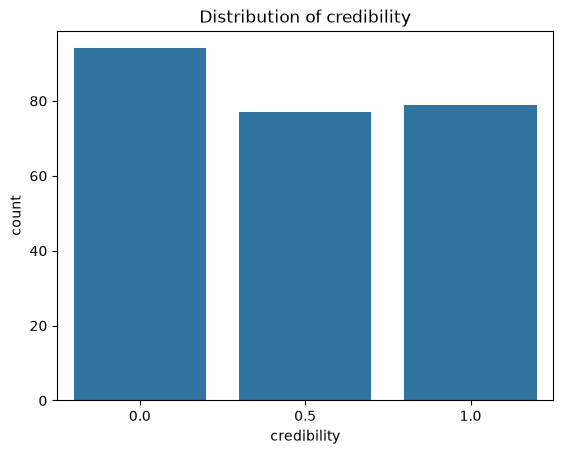


Distribution of competitiveness:
competitiveness
0.0    103
0.5     56
1.0     91
Name: count, dtype: int64


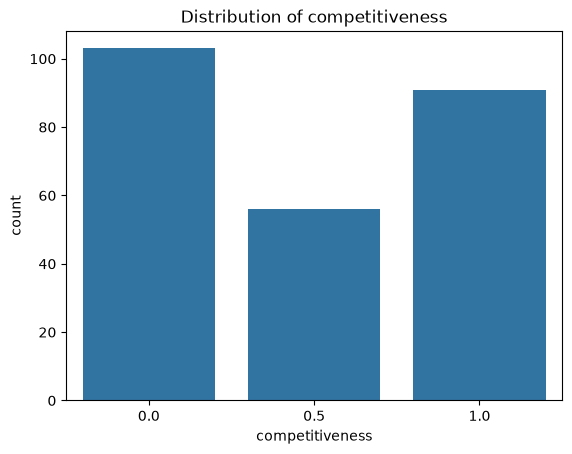


Distribution of operating_risk:
operating_risk
0.0     79
0.5     57
1.0    114
Name: count, dtype: int64


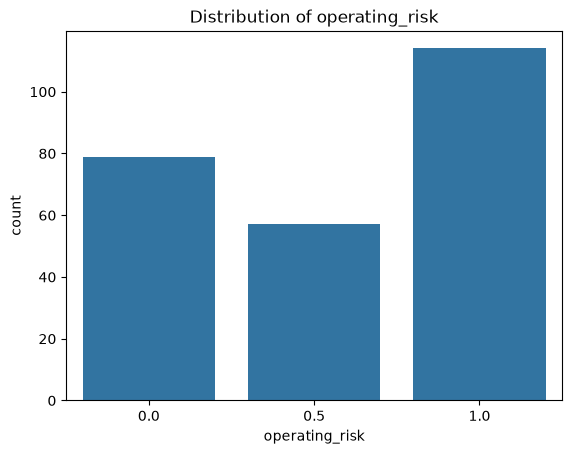

In [13]:

# Count the values of each input feature

for column in features:
    print(f"\nDistribution of {column}:")
    print(df[column].value_counts().sort_index())

    # Plot the counts
    sns.countplot(data=df, x=column)
    plt.title(f"Distribution of {column}")
    plt.show()


class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

Class percentages:
class
non-bankruptcy    57.2
bankruptcy        42.8
Name: proportion, dtype: float64


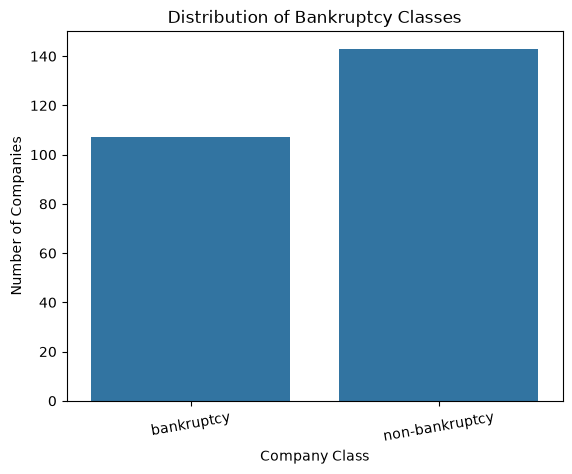

In [14]:
# Analyze the target variable

# Count companies in each class
print(df["class"].value_counts())

# Calculate class percentages
print("\nClass percentages:")
print(df["class"].value_counts(normalize=True) * 100)

# Plot the number of companies in each class
sns.countplot(data=df, x="class")

plt.title("Distribution of Bankruptcy Classes")
plt.xlabel("Company Class")
plt.ylabel("Number of Companies")
plt.xticks(rotation=10)
plt.show()


In [15]:
## descriptive statistics
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


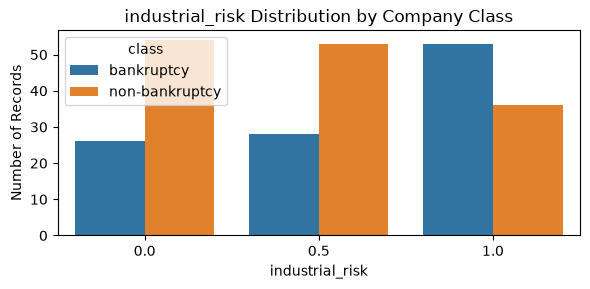

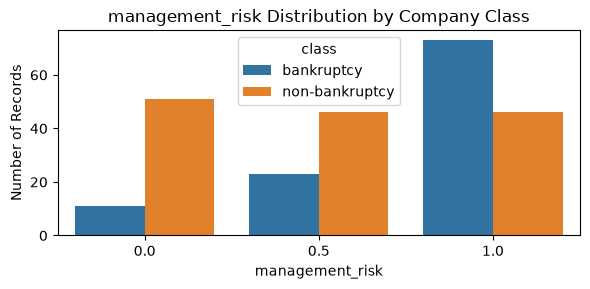

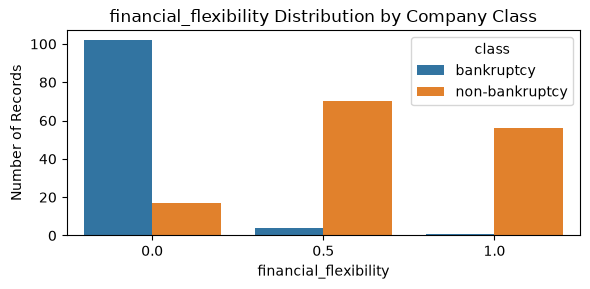

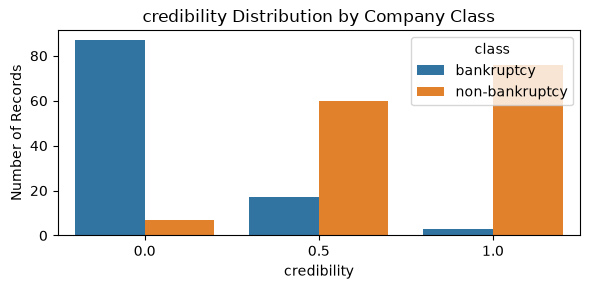

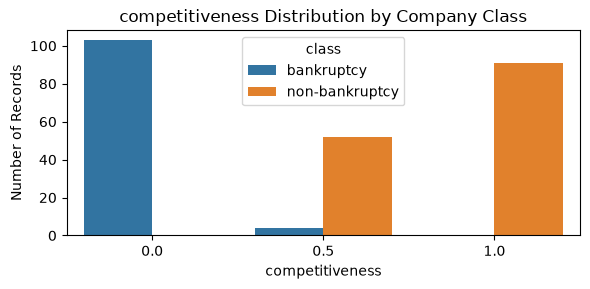

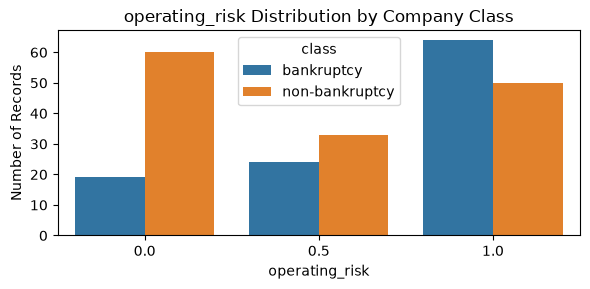

In [16]:
# Plot the distribution of each feature

# Select the six input features
features = df.columns.drop("class")

# Create one chart for each feature
for column in features:
    plt.figure(figsize=(6, 3))

    sns.countplot(data=df, x=column, hue="class")

    plt.title(f"{column} Distribution by Company Class")
    plt.xlabel(column)
    plt.ylabel("Number of Records")

    plt.tight_layout()
    plt.show()


In [17]:
# Compare feature averages by class

# Group companies by their target class
# Calculate the average of each input feature in each group
class_comparison = df.groupby("class")[features].mean()

display(class_comparison)


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
class,,,,,,
bankruptcy,0.626168,0.789720,0.028037,0.107477,0.018692,0.710280
non-bankruptcy,0.437063,0.482517,0.636364,0.741259,0.818182,0.465035


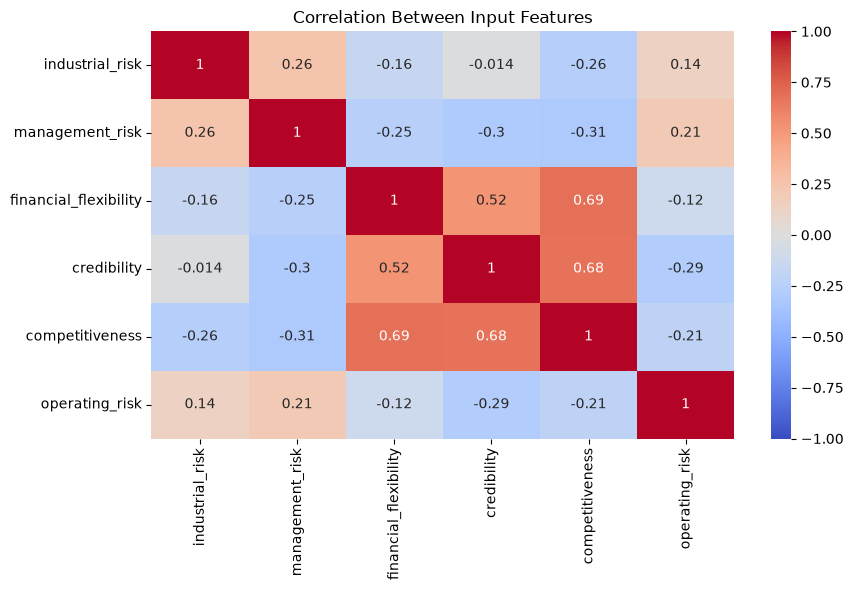

In [18]:
# Correlation heatmap

# Calculate correlations between the six input features
correlation_matrix = df[features].corr()

# Display the correlation matrix as a heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,       # Show correlation values
    cmap="coolwarm",  # Color scheme
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Input Features")
plt.tight_layout()
plt.show()


In [19]:

# Check whether identical input features have different target labels

features = df.drop(columns=["class"]).columns.tolist()

# Count how many distinct classes occur for each feature combination
class_counts = df.groupby(features)["class"].nunique()

# Feature combinations associated with more than one class
conflicting_patterns = class_counts[class_counts > 1]

print("Unique feature combinations:", len(class_counts))
print("Combinations with conflicting labels:", len(conflicting_patterns))
print("Repeated feature combinations:", df.duplicated(
    subset=features
).sum())


Unique feature combinations: 103
Combinations with conflicting labels: 0
Repeated feature combinations: 147


## Build and compare five machine learning models

In [20]:
## Prepare the features and target

# Import the libraries required for model building

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Separate the input features from the target
X = df.drop(columns=["class"])

# Clean spaces and standardize target labels
y = df["class"].astype(str).str.strip().str.lower()

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (200, 6)
Testing shape: (50, 6)


In [21]:
## Creating 5 models


# Create a dictionary containing five classification models

models = {

    # Model 1: Logistic Regression
    # Scaling helps this model work with comparable feature scales.
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    # Model 2: Decision Tree
    # Learns decision rules from the feature values.
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    # Model 3: Random Forest
    # Combines many decision trees.
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    # Model 4: Support Vector Classifier
    # Scaling is useful for SVC.
    "SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),

    # Model 5: K-Nearest Neighbors
    # Scaling helps distance calculations.
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

print("Five models are ready for training.")


Five models are ready for training.


In [22]:
## Train all five models and compare them


# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store each model's evaluation results
results = []

# Train and evaluate each model
for name, model in models.items():

    # Step 1: Train the model
    model.fit(X_train, y_train)

    # Step 2: Predict the test-set classes
    y_pred = model.predict(X_test)

    # Step 3: Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),

        # Treat bankruptcy as the positive class
        "Precision": precision_score(
            y_test, y_pred,
            pos_label="bankruptcy",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, y_pred,
            pos_label="bankruptcy",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, y_pred,
            pos_label="bankruptcy",
            zero_division=0
        )
    })

# Convert the results into a table
results_df = pd.DataFrame(results)

# Sort by F1 score for an initial comparison
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,1.00,1.000,1.0,1.000
1,Decision Tree,1.00,1.000,1.0,1.000
2,Random Forest,1.00,1.000,1.0,1.000
3,SVC,1.00,1.000,1.0,1.000
4,KNN,0.96,0.913,1.0,0.955


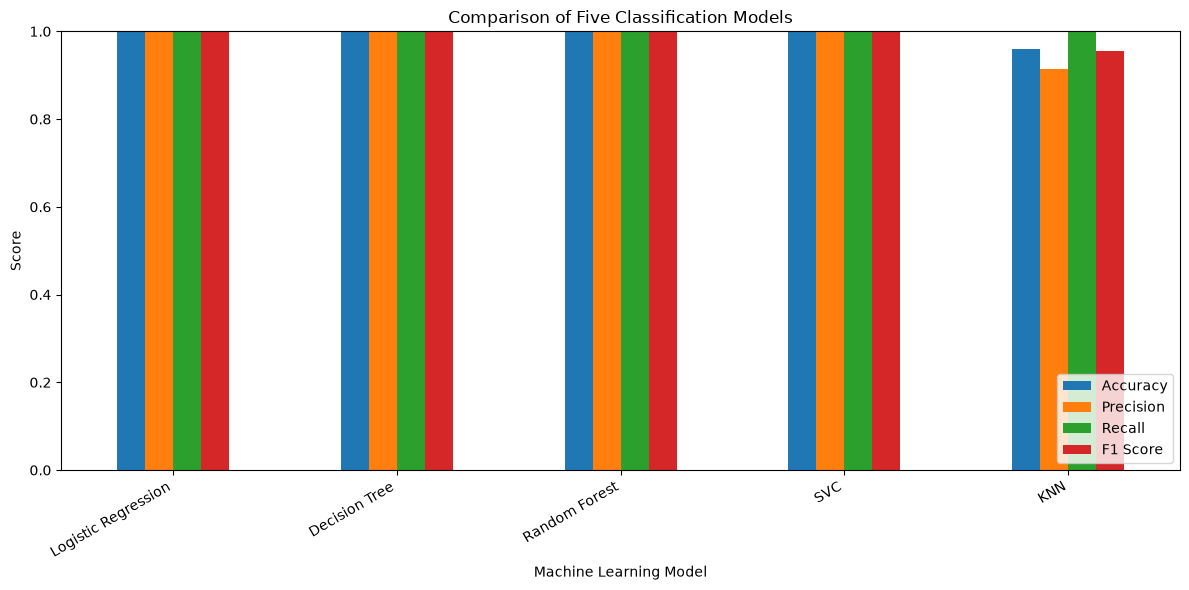

In [23]:
## Visualizing the comparison

# Compare the models using a bar chart

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Five Classification Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

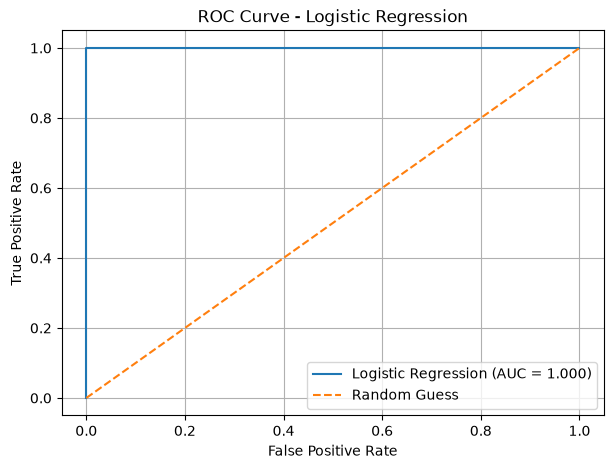

ROC-AUC Score: 1.0


In [24]:
# Step 1: Import the required tools
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Step 2: Select Logistic Regression
selected_model = models["Logistic Regression"]

# Step 3: Train the model on the training data
selected_model.fit(X_train, y_train)

# Step 4: Get the probability of bankruptcy
y_prob = selected_model.predict_proba(X_test)

# Find the column corresponding to the bankruptcy class
bankruptcy_index = list(selected_model.classes_).index("bankruptcy")

y_prob_bankruptcy = y_prob[:, bankruptcy_index]

# Step 5: Convert the actual labels into binary values
y_test_binary = (y_test == "bankruptcy").astype(int)

# Step 6: Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    y_prob_bankruptcy
)

# Step 7: Calculate ROC-AUC score
auc_score = roc_auc_score(
    y_test_binary,
    y_prob_bankruptcy
)

# Step 8: Plot the ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

# Random-guess baseline
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC Score:", round(auc_score, 3))

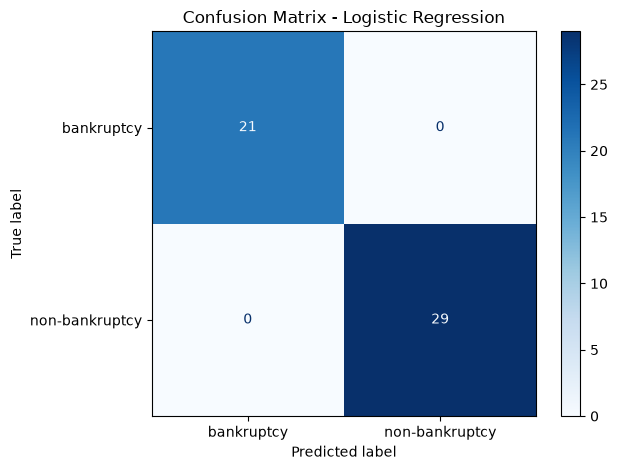

In [25]:
# Confusion Matrix for the selected deployment model

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

selected_model_name = "Logistic Regression"
selected_model = models[selected_model_name]

# Generate predictions for the test set
y_pred = selected_model.predict(X_test)

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["bankruptcy", "non-bankruptcy"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix - {selected_model_name}")
plt.tight_layout()
plt.show()


In [26]:

# Step 1: Import the required evaluation tools

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
import pandas as pd

# Step 2: Create groups from identical feature combinations
# Identical feature rows will always belong to the same group.
groups = X.astype(str).agg("|".join, axis=1)

# Step 3: Explicitly define bankruptcy as the positive class
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="bankruptcy",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="bankruptcy",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="bankruptcy",
        zero_division=0
    )
}

# Step 4: Create five stratified folds, keeping identical
# feature combinations together.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 5: Train and evaluate each model across the folds
cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        groups=groups,
        scoring=scoring_metrics,
        n_jobs=1,
        error_score="raise"
    )

    # Store the average score across five folds
    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1 Score": scores["test_f1"].mean()
    })

# Step 6: Display the final comparison

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean F1 Score",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))

# Identify the model with the highest mean F1 score
best_cv_model = cv_results_df.iloc[0]["Model"]

print("Best model based on mean F1 score:", best_cv_model)
print(
    "Mean F1 score:",
    round(cv_results_df.iloc[0]["Mean F1 Score"], 4)
)


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1 Score
0,Logistic Regression,0.996,1.0000,0.9909,0.9953
1,KNN,0.984,0.9739,0.9909,0.9818
2,Random Forest,0.984,1.0000,0.9619,0.9789
3,SVC,0.980,1.0000,0.9528,0.9743
4,Decision Tree,0.960,0.9514,0.9619,0.9532


Best model based on mean F1 score: Logistic Regression
Mean F1 score: 0.9953



### Model Evaluation Conclusion

Five classification models were compared using accuracy,
precision, recall, and F1 score.

The initial random train-test split produced very high
scores. However, the dataset contains 147 duplicate rows,
so these results may be overly optimistic.

StratifiedGroupKFold cross-validation was used to keep
identical input-feature combinations together during
evaluation.

The model with the highest mean F1 score in the
cross-validation results was selected for deployment.

Further validation on independent company data is
recommended before real-world use.


In [27]:
import joblib
import os

# Select the best model from Cell 35
best_model = models[best_cv_model]

# Train the selected model
best_model.fit(X, y)

# Save the model for Streamlit
joblib.dump(best_model, "bankruptcy_model.pkl")

print("Selected model:", best_cv_model)
print("Model saved successfully!")
print("Saved location:", os.path.abspath("bankruptcy_model.pkl"))


Selected model: Logistic Regression
Model saved successfully!
Saved location: C:\Users\cool\DataScienceCourse\Bankruptcy_Prevention Project\bankruptcy_model.pkl


In [28]:
import joblib

model = joblib.load("bankruptcy_model.pkl")

print("Model loaded successfully!")
print(type(model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [29]:
features = [
    "industrial_risk",
    "management_risk",
    "financial_flexibility",
    "credibility",
    "competitiveness",
    "operating_risk"
]

# Find rows where all six indicators are zero
matching_rows = df[(df[features] == 0.0).all(axis=1)]

print("Number of matching rows:", len(matching_rows))

if len(matching_rows) > 0:
    print("\nActual class labels:")
    print(matching_rows["class"].value_counts())
    print("\nMatching rows:")
    display(matching_rows)
else:
    print("No rows with all six indicators equal to zero.")

Number of matching rows: 0
No rows with all six indicators equal to zero.
